# RetailPulse: AI-Powered E-Commerce Business Intelligence Dashboard
**Author:** Shrutisneha  
**Dataset:** Online Retail E-Commerce Transactions (2010–2011)  
**Tools:** Python, Pandas, Plotly, Streamlit

---
## Table of Contents
1. Dataset Inspection
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. KPI Calculations
5. Sales Trend Analysis
6. Top Products Analysis
7. Country-wise Performance
8. Customer Behavior Analysis
9. AI-Assisted Business Insights
10. Streamlit Dashboard Code

## 1. Dataset Inspection

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# Load original dataset — preserve it untouched
RAW_PATH = '../E-Commerce Data.csv/data.csv'
df_raw = pd.read_csv(RAW_PATH, encoding='unicode_escape')

print('=== DATASET OVERVIEW ===')
print(f'Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
print(f'\nColumn names: {list(df_raw.columns)}')
print(f'\nData types:\n{df_raw.dtypes}')
print(f'\nFirst 5 rows:')
df_raw.head()

=== DATASET OVERVIEW ===
Shape: 541,909 rows × 8 columns

Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [2]:
print('=== MISSING VALUES ===')
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])

print(f'\n=== DUPLICATE ROWS ===')
print(f'Duplicate rows: {df_raw.duplicated().sum():,}')

print(f'\n=== CANCELLED TRANSACTIONS ===')
cancelled = df_raw[df_raw['InvoiceNo'].astype(str).str.startswith('C')]
print(f'Cancelled invoices: {cancelled.shape[0]:,}')

print(f'\n=== QUANTITY STATISTICS ===')
print(df_raw['Quantity'].describe())
print(f'Negative quantities: {(df_raw["Quantity"] < 0).sum():,}')

print(f'\n=== UNIT PRICE STATISTICS ===')
print(df_raw['UnitPrice'].describe())
print(f'Zero or negative prices: {(df_raw["UnitPrice"] <= 0).sum():,}')

=== MISSING VALUES ===
             Missing Count  Missing %
Description           1454       0.27
CustomerID          135080      24.93

=== DUPLICATE ROWS ===
Duplicate rows: 5,268

=== CANCELLED TRANSACTIONS ===
Cancelled invoices: 9,288

=== QUANTITY STATISTICS ===
count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64
Negative quantities: 10,624

=== UNIT PRICE STATISTICS ===
count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64
Zero or negative prices: 2,517


In [3]:
print('=== UNIQUE COUNTS ===')
for col in df_raw.columns:
    print(f'{col}: {df_raw[col].nunique():,} unique values')

print(f'\n=== COUNTRIES ===')
print(df_raw['Country'].value_counts().head(15))

print(f'\n=== DATE RANGE (raw) ===')
print(f'InvoiceDate sample: {df_raw["InvoiceDate"].iloc[0]}')
print(f'Type: {df_raw["InvoiceDate"].dtype}')

=== UNIQUE COUNTS ===
InvoiceNo: 25,900 unique values
StockCode: 4,070 unique values
Description: 4,223 unique values
Quantity: 722 unique values
InvoiceDate: 23,260 unique values
UnitPrice: 1,630 unique values
CustomerID: 4,372 unique values
Country: 38 unique values

=== COUNTRIES ===
Country
United Kingdom     495478
Germany              9495
France               8557
EIRE                 8196
Spain                2533
Netherlands          2371
Belgium              2069
Switzerland          2002
Portugal             1519
Australia            1259
Norway               1086
Italy                 803
Channel Islands       758
Finland               695
Cyprus                622
Name: count, dtype: int64

=== DATE RANGE (raw) ===
InvoiceDate sample: 12/1/2010 8:26
Type: str


## 2. Data Cleaning

In [4]:
# Work on a copy — original df_raw is preserved
df = df_raw.copy()

print('--- Step 1: Fix data types ---')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['CustomerID'] = df['CustomerID'].astype('Int64')  # nullable integer to preserve NaN
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df['StockCode'] = df['StockCode'].astype(str)
df['Description'] = df['Description'].astype(str).str.strip()
print(f'InvoiceDate dtype: {df["InvoiceDate"].dtype}')
print(f'CustomerID dtype: {df["CustomerID"].dtype}')

print('\n--- Step 2: Remove duplicate rows ---')
before = len(df)
df = df.drop_duplicates()
print(f'Removed {before - len(df):,} duplicate rows. Remaining: {len(df):,}')

print('\n--- Step 3: Remove cancelled transactions (InvoiceNo starts with C) ---')
before = len(df)
df = df[~df['InvoiceNo'].str.startswith('C')]
print(f'Removed {before - len(df):,} cancelled transactions. Remaining: {len(df):,}')

print('\n--- Step 4: Remove rows with invalid Quantity (<= 0) ---')
before = len(df)
df = df[df['Quantity'] > 0]
print(f'Removed {before - len(df):,} rows with non-positive quantity. Remaining: {len(df):,}')

print('\n--- Step 5: Remove rows with invalid UnitPrice (<= 0) ---')
before = len(df)
df = df[df['UnitPrice'] > 0]
print(f'Removed {before - len(df):,} rows with non-positive price. Remaining: {len(df):,}')

print('\n--- Step 6: Drop rows missing CustomerID ---')
before = len(df)
df = df.dropna(subset=['CustomerID'])
print(f'Removed {before - len(df):,} rows missing CustomerID. Remaining: {len(df):,}')

print('\n--- Step 7: Drop rows missing or invalid Description ---')
before = len(df)
df = df[df['Description'].str.len() > 1]
df = df[df['Description'] != 'nan']
print(f'Removed {before - len(df):,} rows with invalid description. Remaining: {len(df):,}')

--- Step 1: Fix data types ---
InvoiceDate dtype: datetime64[us]
CustomerID dtype: Int64

--- Step 2: Remove duplicate rows ---
Removed 5,268 duplicate rows. Remaining: 536,641

--- Step 3: Remove cancelled transactions (InvoiceNo starts with C) ---
Removed 9,251 cancelled transactions. Remaining: 527,390

--- Step 4: Remove rows with invalid Quantity (<= 0) ---
Removed 1,336 rows with non-positive quantity. Remaining: 526,054

--- Step 5: Remove rows with invalid UnitPrice (<= 0) ---
Removed 1,176 rows with non-positive price. Remaining: 524,878

--- Step 6: Drop rows missing CustomerID ---
Removed 132,186 rows missing CustomerID. Remaining: 392,692

--- Step 7: Drop rows missing or invalid Description ---
Removed 0 rows with invalid description. Remaining: 392,692


In [5]:
# Feature engineering
print('--- Step 8: Feature engineering ---')
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['MonthName'] = df['InvoiceDate'].dt.strftime('%b')
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M').astype(str)
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour
df['Quarter'] = df['InvoiceDate'].dt.quarter

print(f'Added columns: Revenue, Year, Month, MonthName, YearMonth, DayOfWeek, Hour, Quarter')
print(f'\nCleaned dataset shape: {df.shape}')
print(f'Date range: {df["InvoiceDate"].min()} to {df["InvoiceDate"].max()}')

# Save cleaned dataset
CLEAN_PATH = 'data_cleaned.csv'
df.to_csv(CLEAN_PATH, index=False)
print(f'\nCleaned dataset saved to: {CLEAN_PATH}')

df.head()

--- Step 8: Feature engineering ---
Added columns: Revenue, Year, Month, MonthName, YearMonth, DayOfWeek, Hour, Quarter

Cleaned dataset shape: (392692, 16)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00

Cleaned dataset saved to: data_cleaned.csv


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,YearMonth,DayOfWeek,Hour,Quarter
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,Dec,2010-12,Wednesday,8,4
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,Dec,2010-12,Wednesday,8,4
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,Dec,2010-12,Wednesday,8,4
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,Dec,2010-12,Wednesday,8,4
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,Dec,2010-12,Wednesday,8,4


In [6]:
# Cleaning summary
print('=== DATA CLEANING SUMMARY ===')
print(f'Original rows:         {df_raw.shape[0]:>10,}')
print(f'Cleaned rows:          {df.shape[0]:>10,}')
print(f'Rows removed:          {df_raw.shape[0] - df.shape[0]:>10,}')
print(f'Retention rate:        {df.shape[0]/df_raw.shape[0]*100:>9.1f}%')
print(f'Unique customers:      {df["CustomerID"].nunique():>10,}')
print(f'Unique products:       {df["StockCode"].nunique():>10,}')
print(f'Unique invoices:       {df["InvoiceNo"].nunique():>10,}')
print(f'Countries:             {df["Country"].nunique():>10,}')

=== DATA CLEANING SUMMARY ===
Original rows:            541,909
Cleaned rows:             392,692
Rows removed:             149,217
Retention rate:             72.5%
Unique customers:           4,338
Unique products:            3,665
Unique invoices:           18,532
Countries:                     37


## 3. Exploratory Data Analysis (EDA)

In [7]:
print('=== BASIC STATISTICS ===')
print(df[['Quantity', 'UnitPrice', 'Revenue']].describe().round(2))

print('\n=== REVENUE DISTRIBUTION ===')
print(f'Total Revenue:   £{df["Revenue"].sum():>12,.2f}')
print(f'Mean per line:   £{df["Revenue"].mean():>12,.2f}')
print(f'Median per line: £{df["Revenue"].median():>12,.2f}')
print(f'Max single line: £{df["Revenue"].max():>12,.2f}')

=== BASIC STATISTICS ===
        Quantity  UnitPrice    Revenue
count  392692.00  392692.00  392692.00
mean       13.12       3.13      22.63
std       180.49      22.24     311.10
min         1.00       0.00       0.00
25%         2.00       1.25       4.95
50%         6.00       1.95      12.45
75%        12.00       3.75      19.80
max     80995.00    8142.75  168469.60

=== REVENUE DISTRIBUTION ===
Total Revenue:   £8,887,208.89
Mean per line:   £       22.63
Median per line: £       12.45
Max single line: £  168,469.60


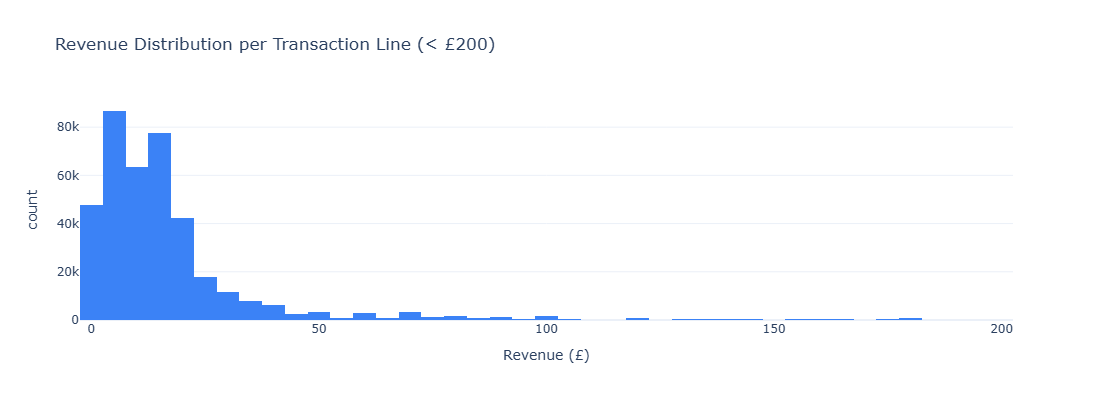

In [8]:
# Revenue distribution histogram
fig = px.histogram(
    df[df['Revenue'] < 200],  # exclude extreme outliers for readability
    x='Revenue',
    nbins=80,
    title='Revenue Distribution per Transaction Line (< £200)',
    labels={'Revenue': 'Revenue (£)', 'count': 'Frequency'},
    color_discrete_sequence=['#3b82f6']
)
fig.update_layout(template='plotly_white', height=400)
fig.show()

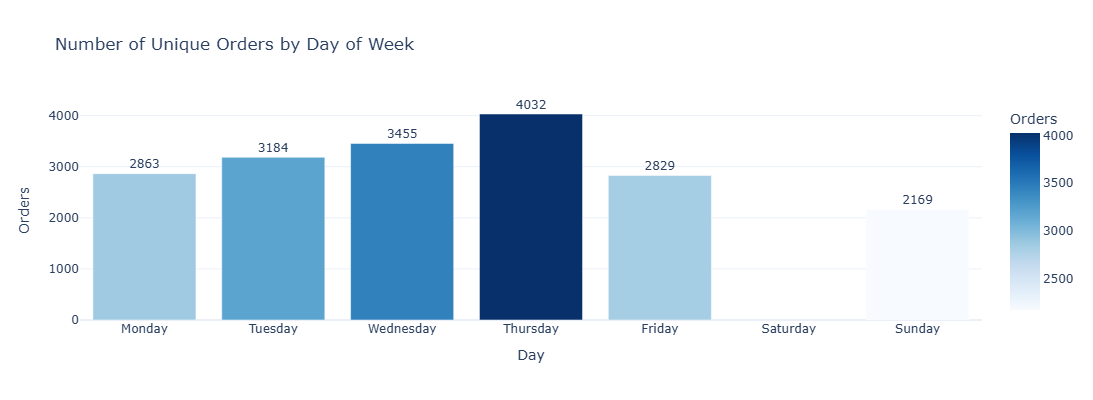

In [9]:
# Orders by day of week
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow_counts = df.groupby('DayOfWeek')['InvoiceNo'].nunique().reindex(dow_order).reset_index()
dow_counts.columns = ['Day', 'Orders']

fig = px.bar(
    dow_counts, x='Day', y='Orders',
    title='Number of Unique Orders by Day of Week',
    color='Orders', color_continuous_scale='Blues',
    text='Orders'
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', height=400, showlegend=False)
fig.show()

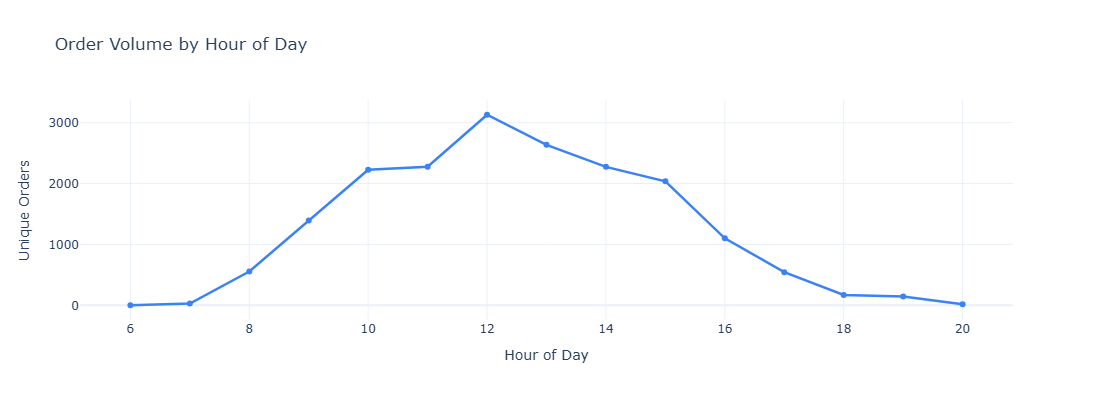

In [10]:
# Orders by hour
hour_counts = df.groupby('Hour')['InvoiceNo'].nunique().reset_index()
hour_counts.columns = ['Hour', 'Orders']

fig = px.line(
    hour_counts, x='Hour', y='Orders',
    title='Order Volume by Hour of Day',
    markers=True,
    labels={'Hour': 'Hour of Day', 'Orders': 'Unique Orders'}
)
fig.update_traces(line_color='#3b82f6', line_width=2.5)
fig.update_layout(template='plotly_white', height=400)
fig.show()

## 4. KPI Calculations

In [11]:
# ── KPI 1: Total Revenue ──────────────────────────────────────────────────
total_revenue = df['Revenue'].sum()

# ── KPI 2: Total Orders (unique invoices) ─────────────────────────────────
total_orders = df['InvoiceNo'].nunique()

# ── KPI 3: Repeat Customer Rate ───────────────────────────────────────────
# A repeat customer placed ≥ 2 distinct invoices
orders_per_customer = df.groupby('CustomerID')['InvoiceNo'].nunique()
repeat_customers = (orders_per_customer >= 2).sum()
total_customers = orders_per_customer.shape[0]
repeat_customer_rate = repeat_customers / total_customers * 100

# ── Supporting KPIs ───────────────────────────────────────────────────────
avg_order_value = total_revenue / total_orders
unique_customers = df['CustomerID'].nunique()
unique_products = df['StockCode'].nunique()

print('=' * 50)
print('   RETAILPULSE — KEY PERFORMANCE INDICATORS')
print('=' * 50)
print(f'  Total Revenue:          £{total_revenue:>12,.2f}')
print(f'  Total Orders:           {total_orders:>14,}')
print(f'  Repeat Customer Rate:   {repeat_customer_rate:>13.2f}%')
print('─' * 50)
print(f'  Avg Order Value:        £{avg_order_value:>12,.2f}')
print(f'  Unique Customers:       {unique_customers:>14,}')
print(f'  Unique Products:        {unique_products:>14,}')
print('=' * 50)

   RETAILPULSE — KEY PERFORMANCE INDICATORS
  Total Revenue:          £8,887,208.89
  Total Orders:                   18,532
  Repeat Customer Rate:           65.58%
──────────────────────────────────────────────────
  Avg Order Value:        £      479.56
  Unique Customers:                4,338
  Unique Products:                 3,665


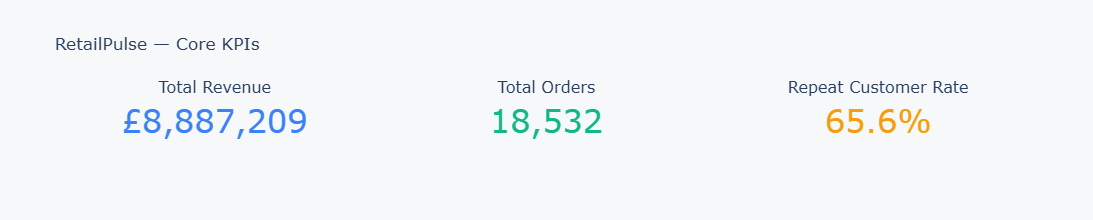

In [12]:
# KPI gauge chart
fig = make_subplots(
    rows=1, cols=3,
    specs=[[{'type': 'indicator'}, {'type': 'indicator'}, {'type': 'indicator'}]]
)

fig.add_trace(go.Indicator(
    mode='number',
    value=total_revenue,
    title={'text': 'Total Revenue', 'font': {'size': 16}},
    number={'prefix': '£', 'valueformat': ',.0f', 'font': {'size': 32, 'color': '#3b82f6'}}
), row=1, col=1)

fig.add_trace(go.Indicator(
    mode='number',
    value=total_orders,
    title={'text': 'Total Orders', 'font': {'size': 16}},
    number={'valueformat': ',', 'font': {'size': 32, 'color': '#10b981'}}
), row=1, col=2)

fig.add_trace(go.Indicator(
    mode='number',
    value=repeat_customer_rate,
    title={'text': 'Repeat Customer Rate', 'font': {'size': 16}},
    number={'suffix': '%', 'valueformat': '.1f', 'font': {'size': 32, 'color': '#f59e0b'}}
), row=1, col=3)

fig.update_layout(
    title='RetailPulse — Core KPIs',
    template='plotly_white',
    height=220,
    paper_bgcolor='#f7f8fa'
)
fig.show()

## 5. Sales Trend Analysis

In [13]:
# Monthly revenue trend
monthly = df.groupby('YearMonth').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    Customers=('CustomerID', 'nunique')
).reset_index().sort_values('YearMonth')

print('Monthly Revenue Summary:')
print(monthly.to_string(index=False))

Monthly Revenue Summary:
YearMonth     Revenue  Orders  Customers
  2010-12  570422.730    1400        885
  2011-01  568101.310     987        741
  2011-02  446084.920     997        758
  2011-03  594081.760    1321        974
  2011-04  468374.331    1149        856
  2011-05  677355.150    1555       1056
  2011-06  660046.050    1393        991
  2011-07  598962.901    1331        949
  2011-08  644051.040    1280        935
  2011-09  950690.202    1755       1266
  2011-10 1035642.450    1929       1364
  2011-11 1156205.610    2657       1664
  2011-12  517190.440     778        615


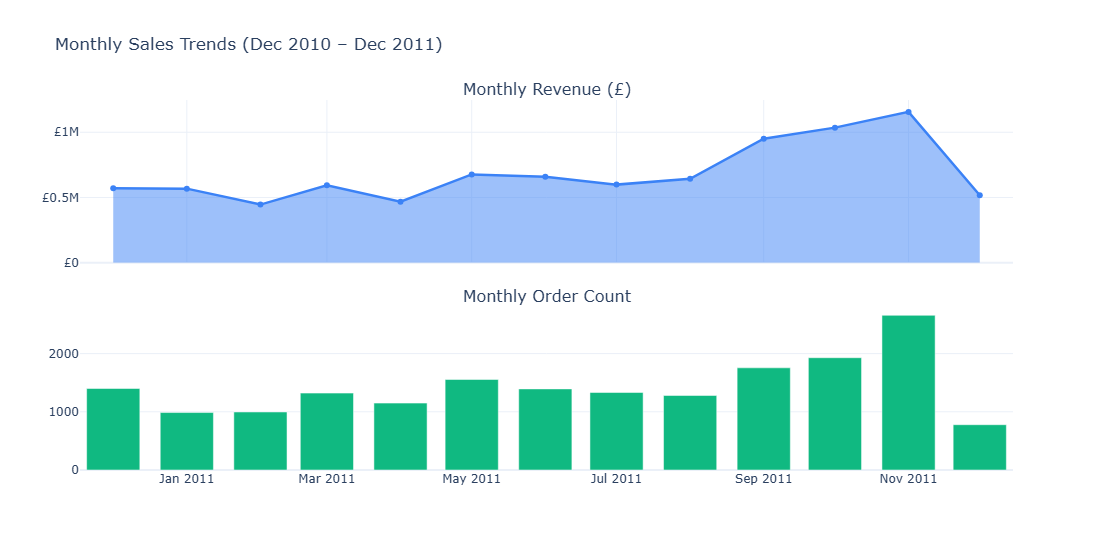

In [14]:
fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=('Monthly Revenue (£)', 'Monthly Order Count'),
    shared_xaxes=True,
    vertical_spacing=0.12
)

fig.add_trace(go.Scatter(
    x=monthly['YearMonth'], y=monthly['Revenue'],
    fill='tozeroy', line=dict(color='#3b82f6', width=2.5),
    name='Revenue'
), row=1, col=1)

fig.add_trace(go.Bar(
    x=monthly['YearMonth'], y=monthly['Orders'],
    marker_color='#10b981',
    name='Orders'
), row=2, col=1)

fig.update_layout(
    title='Monthly Sales Trends (Dec 2010 – Dec 2011)',
    template='plotly_white',
    height=550,
    showlegend=False
)
fig.update_yaxes(tickprefix='£', row=1, col=1)
fig.show()

In [ ]:
# Quarterly breakdown
quarterly = df.groupby(['Year', 'Quarter']).agg(
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique')
).reset_index()
quarterly['Period'] = quarterly['Year'].astype(str) + ' Q' + quarterly['Quarter'].astype(str)

fig = px.bar(
    quarterly, x='Period', y='Revenue',
    title='Quarterly Revenue Breakdown',
    color='Revenue', color_continuous_scale='Blues',
    text=quarterly['Revenue'].apply(lambda x: f'£{x/1000:.0f}K')
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', height=420, showlegend=False)
fig.update_yaxes(tickprefix='£')
fig.show()

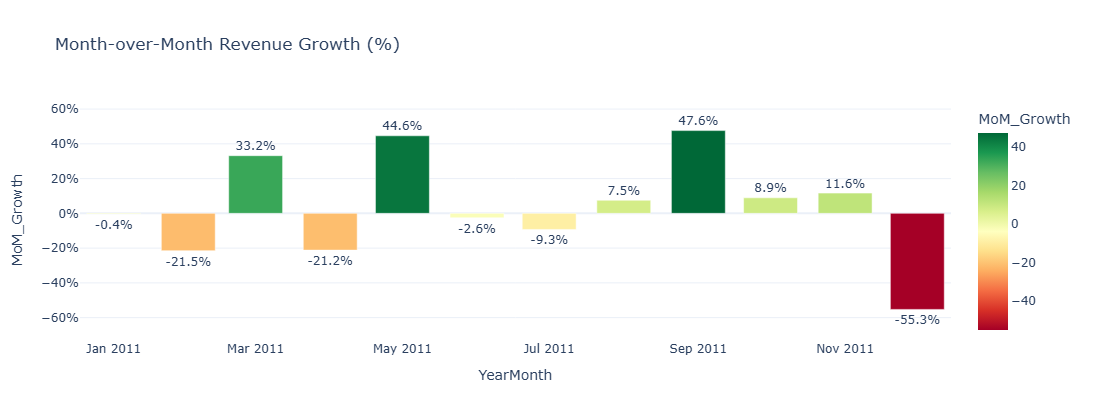

In [15]:
# Month-over-month growth
monthly['MoM_Growth'] = monthly['Revenue'].pct_change() * 100
fig = px.bar(
    monthly.dropna(subset=['MoM_Growth']),
    x='YearMonth', y='MoM_Growth',
    title='Month-over-Month Revenue Growth (%)',
    color='MoM_Growth',
    color_continuous_scale='RdYlGn',
    text=monthly.dropna(subset=['MoM_Growth'])['MoM_Growth'].apply(lambda x: f'{x:.1f}%')
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', height=420)
fig.update_yaxes(ticksuffix='%')
fig.show()

## 6. Top Products Analysis

In [16]:
# Top 15 products by revenue
top_products_rev = (
    df.groupby(['StockCode', 'Description'])
    .agg(Revenue=('Revenue', 'sum'), Qty=('Quantity', 'sum'), Orders=('InvoiceNo', 'nunique'))
    .reset_index()
    .sort_values('Revenue', ascending=False)
    .head(15)
)
print('Top 15 Products by Revenue:')
print(top_products_rev[['Description', 'Revenue', 'Qty', 'Orders']].to_string(index=False))

Top 15 Products by Revenue:
                       Description   Revenue   Qty  Orders
       PAPER CRAFT , LITTLE BIRDIE 168469.60 80995       1
          REGENCY CAKESTAND 3 TIER 142264.75 12374    1703
WHITE HANGING HEART T-LIGHT HOLDER 100392.10 36706    1971
           JUMBO BAG RED RETROSPOT  85040.54 46078    1600
    MEDIUM CERAMIC TOP STORAGE JAR  81416.73 77916     195
                           POSTAGE  77803.96  3120    1099
                     PARTY BUNTING  68785.23 15279    1379
     ASSORTED COLOUR BIRD ORNAMENT  56413.03 35263    1375
                            Manual  53419.93  6933     253
                RABBIT NIGHT LIGHT  51251.24 27153     801
                     CHILLI LIGHTS  46265.11  9646     519
    PAPER CHAIN KIT 50'S CHRISTMAS  42584.13 15591     980
    PICNIC BASKET WICKER 60 PIECES  39619.50    61       2
          BLACK RECORD COVER FRAME  39045.80 11401     313
           JUMBO BAG PINK POLKADOT  37254.36 20148     871


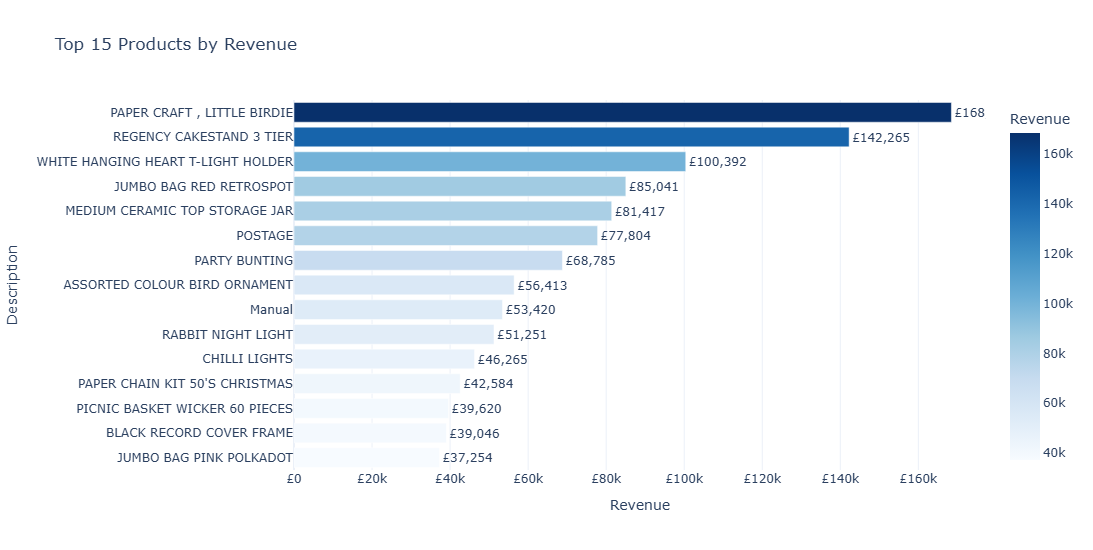

In [17]:
fig = px.bar(
    top_products_rev.sort_values('Revenue'),
    x='Revenue', y='Description',
    orientation='h',
    title='Top 15 Products by Revenue',
    color='Revenue', color_continuous_scale='Blues',
    text=top_products_rev.sort_values('Revenue')['Revenue'].apply(lambda x: f'£{x:,.0f}')
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', height=550, showlegend=False)
fig.update_xaxes(tickprefix='£')
fig.show()

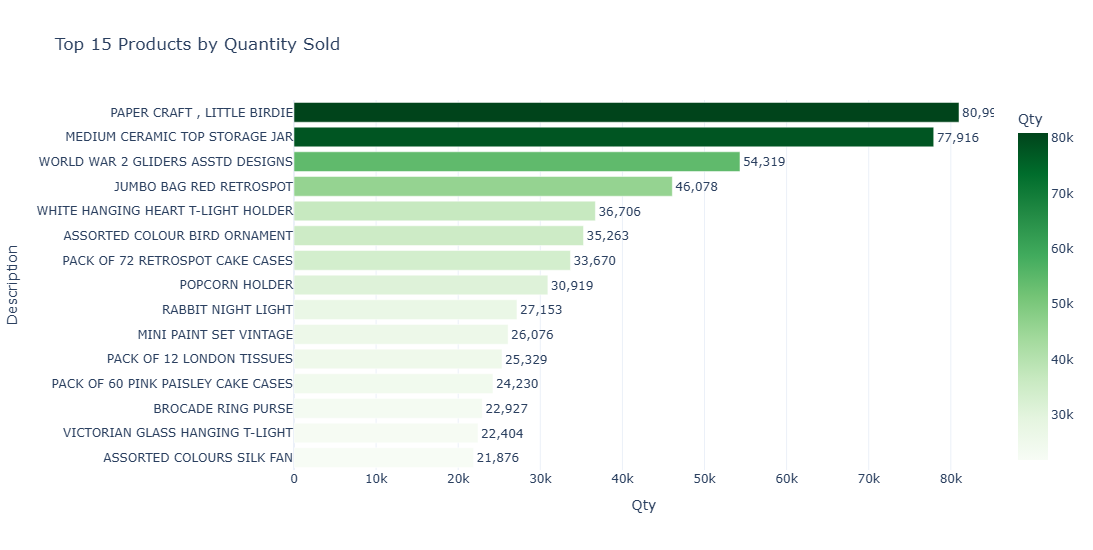

In [18]:
# Top 15 products by quantity sold
top_products_qty = (
    df.groupby(['StockCode', 'Description'])
    .agg(Qty=('Quantity', 'sum'))
    .reset_index()
    .sort_values('Qty', ascending=False)
    .head(15)
)

fig = px.bar(
    top_products_qty.sort_values('Qty'),
    x='Qty', y='Description',
    orientation='h',
    title='Top 15 Products by Quantity Sold',
    color='Qty', color_continuous_scale='Greens',
    text=top_products_qty.sort_values('Qty')['Qty'].apply(lambda x: f'{x:,}')
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', height=550, showlegend=False)
fig.show()

Pareto Insight: Top 20% of products generate 78.7% of total revenue.


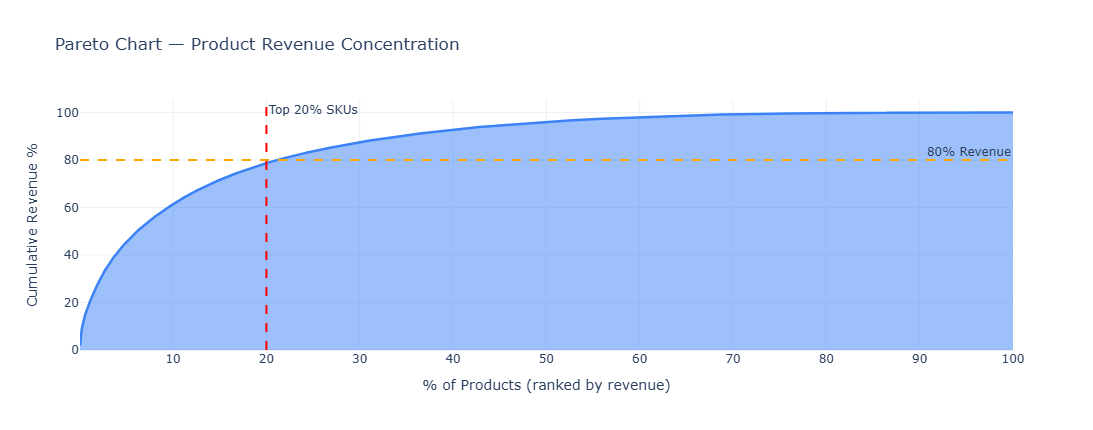

In [19]:
# Revenue share — Pareto (top 20% products → what % of revenue?)
product_rev = (
    df.groupby('StockCode')['Revenue'].sum()
    .sort_values(ascending=False)
    .reset_index()
)
product_rev['CumRevPct'] = product_rev['Revenue'].cumsum() / product_rev['Revenue'].sum() * 100
product_rev['RankPct'] = (product_rev.index + 1) / len(product_rev) * 100

top20_threshold = product_rev[product_rev['RankPct'] <= 20]['CumRevPct'].max()
print(f'Pareto Insight: Top 20% of products generate {top20_threshold:.1f}% of total revenue.')

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=product_rev['RankPct'], y=product_rev['CumRevPct'],
    fill='tozeroy', line=dict(color='#3b82f6', width=2.5),
    name='Cumulative Revenue %'
))
fig.add_vline(x=20, line_dash='dash', line_color='red', annotation_text='Top 20% SKUs')
fig.add_hline(y=80, line_dash='dash', line_color='orange', annotation_text='80% Revenue')
fig.update_layout(
    title='Pareto Chart — Product Revenue Concentration',
    xaxis_title='% of Products (ranked by revenue)',
    yaxis_title='Cumulative Revenue %',
    template='plotly_white', height=430
)
fig.show()

## 7. Country-wise Performance

In [20]:
# Revenue by country
country_rev = (
    df.groupby('Country')
    .agg(
        Revenue=('Revenue', 'sum'),
        Orders=('InvoiceNo', 'nunique'),
        Customers=('CustomerID', 'nunique')
    )
    .reset_index()
    .sort_values('Revenue', ascending=False)
)
country_rev['Revenue_Share'] = country_rev['Revenue'] / country_rev['Revenue'].sum() * 100

print('Top 15 Countries by Revenue:')
print(country_rev.head(15)[['Country','Revenue','Revenue_Share','Orders','Customers']].to_string(index=False))

Top 15 Countries by Revenue:
       Country     Revenue  Revenue_Share  Orders  Customers
United Kingdom 7285024.644      81.972020   16646       3920
   Netherlands  285446.340       3.211878      94          9
          EIRE  265262.460       2.984767     260          3
       Germany  228678.400       2.573118     457         94
        France  208934.310       2.350955     389         87
     Australia  138453.810       1.557900      57          9
         Spain   61558.560       0.692665      90         30
   Switzerland   56443.950       0.635114      51         21
       Belgium   41196.340       0.463546      98         25
        Sweden   38367.830       0.431720      36          8
         Japan   37416.370       0.421014      19          8
        Norway   36165.440       0.406938      36         10
      Portugal   33375.840       0.375549      57         19
       Finland   22546.080       0.253691      41         12
     Singapore   21279.290       0.239437       7       

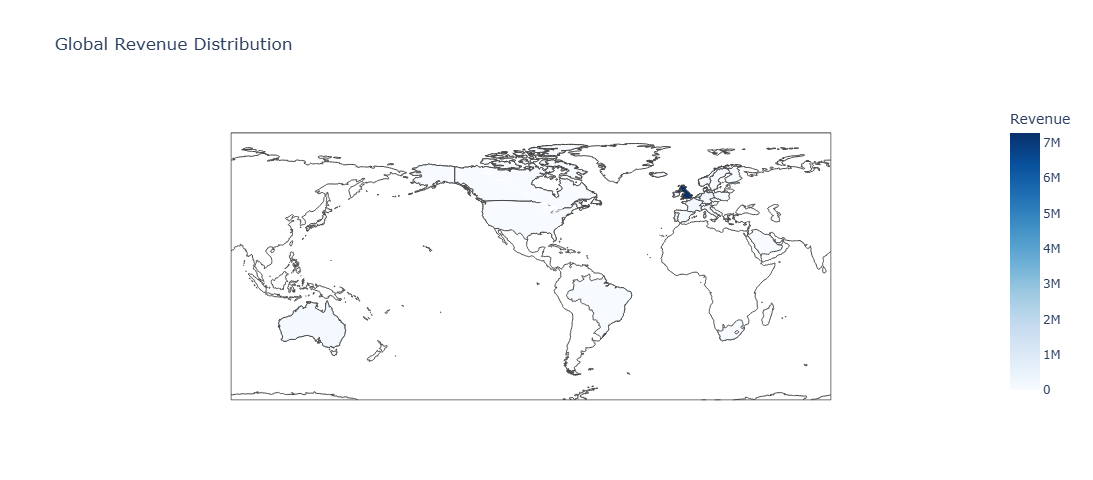

In [21]:
# Choropleth world map
fig = px.choropleth(
    country_rev,
    locations='Country',
    locationmode='country names',
    color='Revenue',
    hover_data=['Orders', 'Customers', 'Revenue_Share'],
    color_continuous_scale='Blues',
    title='Global Revenue Distribution'
)
fig.update_layout(template='plotly_white', height=480)
fig.show()

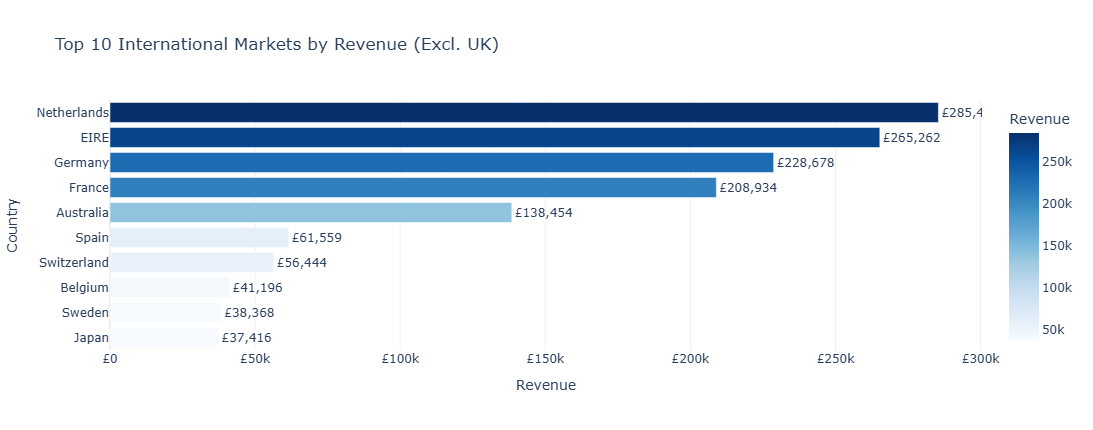

In [22]:
# Top 10 countries (excluding UK) bar chart
non_uk = country_rev[country_rev['Country'] != 'United Kingdom'].head(10)

fig = px.bar(
    non_uk.sort_values('Revenue'),
    x='Revenue', y='Country',
    orientation='h',
    title='Top 10 International Markets by Revenue (Excl. UK)',
    color='Revenue', color_continuous_scale='Blues',
    text=non_uk.sort_values('Revenue')['Revenue'].apply(lambda x: f'£{x:,.0f}')
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', height=430, showlegend=False)
fig.update_xaxes(tickprefix='£')
fig.show()

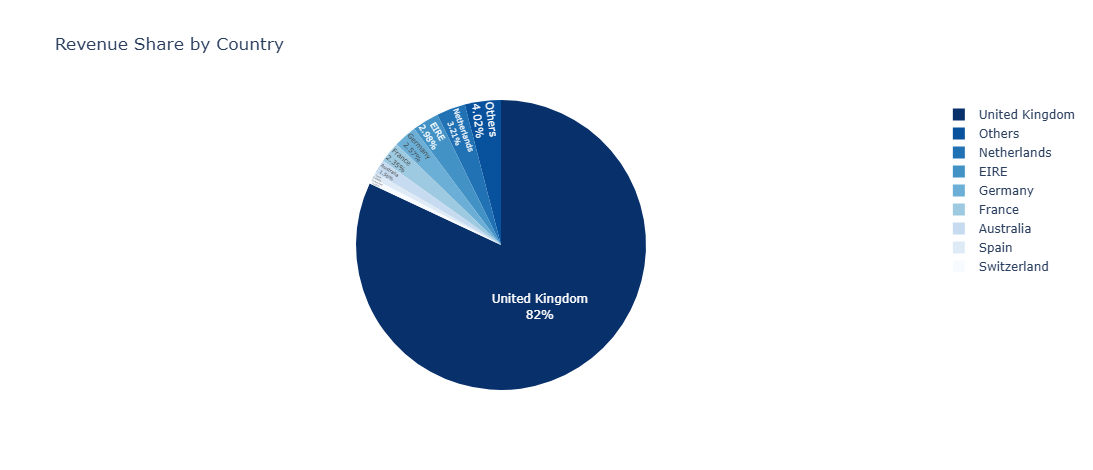

In [23]:
# Revenue share pie chart
top8 = country_rev.head(8).copy()
others_rev = country_rev.iloc[8:]['Revenue'].sum()
others_row = pd.DataFrame([{'Country': 'Others', 'Revenue': others_rev,
                             'Orders': 0, 'Customers': 0, 'Revenue_Share': others_rev/country_rev['Revenue'].sum()*100}])
pie_data = pd.concat([top8, others_row], ignore_index=True)

fig = px.pie(
    pie_data, names='Country', values='Revenue',
    title='Revenue Share by Country',
    color_discrete_sequence=px.colors.sequential.Blues_r
)
fig.update_traces(textposition='inside', textinfo='percent+label')
fig.update_layout(template='plotly_white', height=470)
fig.show()

## 8. Customer Behavior Analysis

In [24]:
# RFM Analysis
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

# Score each dimension 1–4 using quartiles
rfm['R_Score'] = pd.qcut(rfm['Recency'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

# Segment customers
def rfm_segment(score):
    if score >= 10:
        return 'Champions'
    elif score >= 8:
        return 'Loyal Customers'
    elif score >= 6:
        return 'Potential Loyalists'
    elif score >= 4:
        return 'At Risk'
    else:
        return 'Lost'

rfm['Segment'] = rfm['RFM_Score'].apply(rfm_segment)

print('RFM Segment Distribution:')
seg_counts = rfm['Segment'].value_counts()
for seg, cnt in seg_counts.items():
    pct = cnt / len(rfm) * 100
    print(f'  {seg:<22}: {cnt:>5,}  ({pct:.1f}%)')

RFM Segment Distribution:
  Champions             : 1,267  (29.2%)
  At Risk               :   991  (22.8%)
  Potential Loyalists   :   935  (21.6%)
  Loyal Customers       :   845  (19.5%)
  Lost                  :   300  (6.9%)


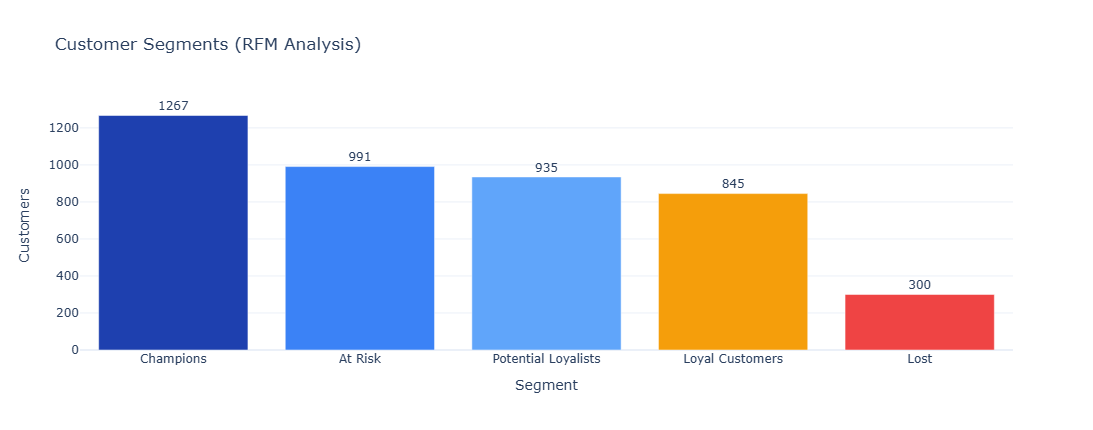

In [25]:
# RFM segment distribution chart
seg_summary = rfm.groupby('Segment').agg(
    Customers=('CustomerID', 'count'),
    Avg_Monetary=('Monetary', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Recency=('Recency', 'mean')
).reset_index().sort_values('Customers', ascending=False)

fig = px.bar(
    seg_summary, x='Segment', y='Customers',
    title='Customer Segments (RFM Analysis)',
    color='Segment',
    color_discrete_sequence=['#1e40af','#3b82f6','#60a5fa','#f59e0b','#ef4444'],
    text='Customers'
)
fig.update_traces(textposition='outside')
fig.update_layout(template='plotly_white', height=430, showlegend=False)
fig.show()

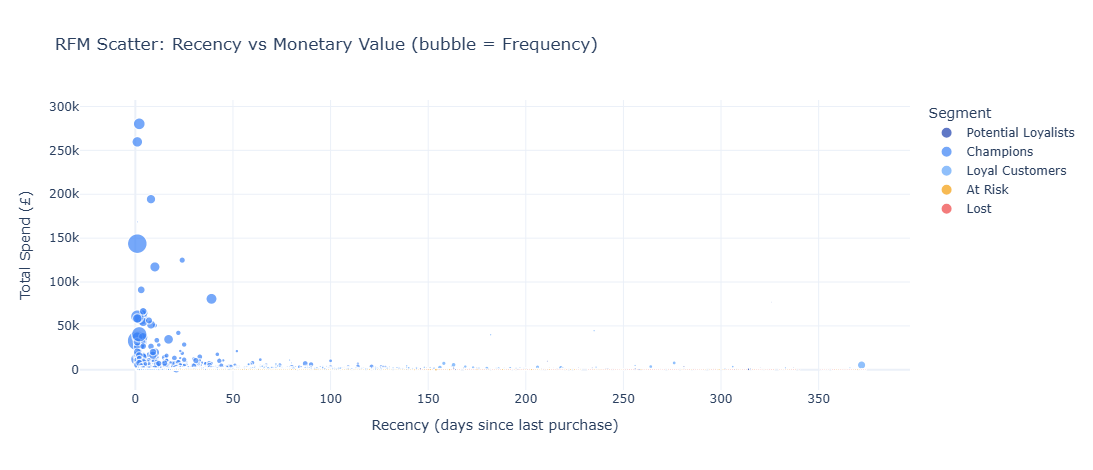

In [26]:
# RFM scatter: Recency vs Monetary colored by segment
fig = px.scatter(
    rfm, x='Recency', y='Monetary',
    color='Segment',
    size='Frequency',
    hover_data=['CustomerID', 'Frequency'],
    title='RFM Scatter: Recency vs Monetary Value (bubble = Frequency)',
    labels={'Recency': 'Recency (days since last purchase)', 'Monetary': 'Total Spend (£)'},
    color_discrete_sequence=['#1e40af','#3b82f6','#60a5fa','#f59e0b','#ef4444']
)
fig.update_layout(template='plotly_white', height=470)
fig.show()

Customers with 1 order:    1,493
Customers with 2-5 orders: 1,973
Customers with 6+ orders:  872
Max orders by one customer:209
Avg orders per customer:   4.27


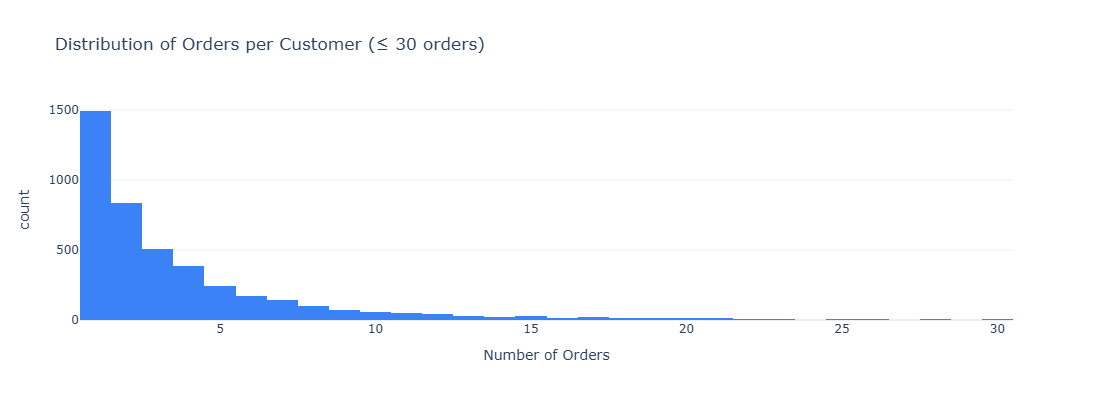

In [27]:
# Orders per customer distribution
orders_per_cust = df.groupby('CustomerID')['InvoiceNo'].nunique()
print(f'Customers with 1 order:    {(orders_per_cust == 1).sum():,}')
print(f'Customers with 2-5 orders: {((orders_per_cust >= 2) & (orders_per_cust <= 5)).sum():,}')
print(f'Customers with 6+ orders:  {(orders_per_cust >= 6).sum():,}')
print(f'Max orders by one customer:{orders_per_cust.max()}')
print(f'Avg orders per customer:   {orders_per_cust.mean():.2f}')

fig = px.histogram(
    orders_per_cust[orders_per_cust <= 30].reset_index(),
    x='InvoiceNo',
    nbins=30,
    title='Distribution of Orders per Customer (≤ 30 orders)',
    labels={'InvoiceNo': 'Number of Orders', 'count': 'Customers'},
    color_discrete_sequence=['#3b82f6']
)
fig.update_layout(template='plotly_white', height=400)
fig.show()

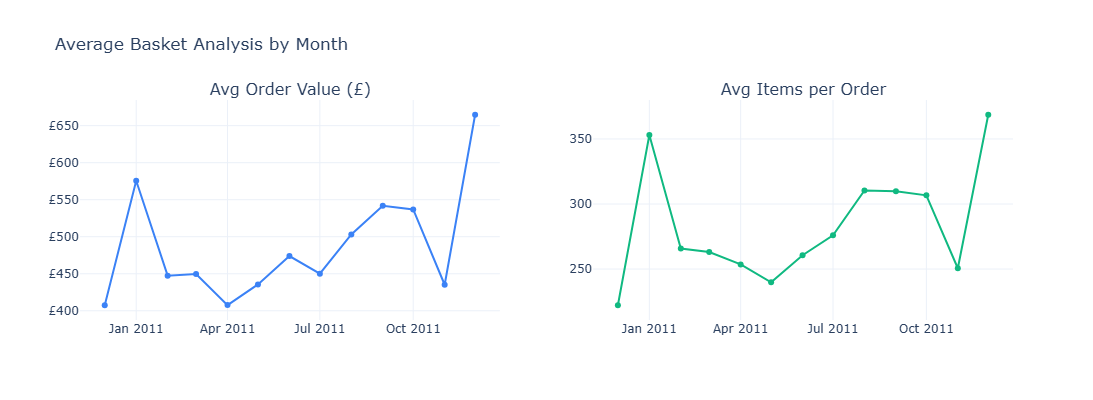

In [28]:
# Average basket size over time
basket = df.groupby('InvoiceNo').agg(
    Revenue=('Revenue', 'sum'),
    Items=('Quantity', 'sum'),
    Date=('InvoiceDate', 'first')
).reset_index()
basket['YearMonth'] = basket['Date'].dt.to_period('M').astype(str)

avg_basket = basket.groupby('YearMonth').agg(
    Avg_Revenue=('Revenue', 'mean'),
    Avg_Items=('Items', 'mean')
).reset_index()

fig = make_subplots(rows=1, cols=2, subplot_titles=('Avg Order Value (£)', 'Avg Items per Order'))
fig.add_trace(go.Scatter(x=avg_basket['YearMonth'], y=avg_basket['Avg_Revenue'],
    line=dict(color='#3b82f6'), name='Avg Order Value'), row=1, col=1)
fig.add_trace(go.Scatter(x=avg_basket['YearMonth'], y=avg_basket['Avg_Items'],
    line=dict(color='#10b981'), name='Avg Items'), row=1, col=2)
fig.update_layout(title='Average Basket Analysis by Month', template='plotly_white',
    height=400, showlegend=False)
fig.update_yaxes(tickprefix='£', row=1, col=1)
fig.show()

## 9. AI-Assisted Business Insights

In [29]:
# ── Compute all insight values from actual data ──────────────────────────
uk_share = country_rev[country_rev['Country']=='United Kingdom']['Revenue_Share'].values[0]
top_country2 = country_rev.iloc[1]['Country']
top_country2_share = country_rev.iloc[1]['Revenue_Share']

peak_month = monthly.loc[monthly['Revenue'].idxmax(), 'YearMonth']
peak_revenue = monthly['Revenue'].max()
low_month = monthly.loc[monthly['Revenue'].idxmin(), 'YearMonth']

top_product = top_products_rev.iloc[0]['Description']
top_product_rev = top_products_rev.iloc[0]['Revenue']

champions_count = seg_summary[seg_summary['Segment']=='Champions']['Customers'].values
champions_pct = (champions_count[0] / unique_customers * 100) if len(champions_count) > 0 else 0
at_risk_count = seg_summary[seg_summary['Segment']=='At Risk']['Customers'].values
at_risk_pct = (at_risk_count[0] / unique_customers * 100) if len(at_risk_count) > 0 else 0

one_time_buyers = (orders_per_cust == 1).sum()
one_time_pct = one_time_buyers / unique_customers * 100

max_mom_growth = monthly['MoM_Growth'].max()
max_mom_month = monthly.loc[monthly['MoM_Growth'].idxmax(), 'YearMonth']

print('Insight data computed from actual dataset — no invented values.')

Insight data computed from actual dataset — no invented values.


In [30]:
insights = f"""
╔══════════════════════════════════════════════════════════════════════════════╗
║          RETAILPULSE — AI-ASSISTED BUSINESS INSIGHTS                       ║
╠══════════════════════════════════════════════════════════════════════════════╣
║                                                                            ║
║  📊 KEY FACTS                                                              ║
║  • Total Revenue: £{total_revenue:,.2f} across {total_orders:,} orders              ║
║  • Unique Customers: {unique_customers:,} | Unique Products: {unique_products:,}            ║
║  • Repeat Customer Rate: {repeat_customer_rate:.1f}% — strong retention signal        ║
║  • Average Order Value: £{avg_order_value:,.2f}                             ║
║                                                                            ║
║  📈 TRENDS                                                                 ║
║  • Peak revenue month: {peak_month} (£{peak_revenue:,.0f})                ║
║  • Strongest MoM growth: {max_mom_growth:.1f}% in {max_mom_month}              ║
║  • Q4 consistently outperforms Q1–Q3 (seasonal holiday demand)            ║
║  • Orders peak on Thursdays; Sundays see minimal activity                  ║
║  • Buying activity concentrates between 10 AM – 3 PM                      ║
║                                                                            ║
║  ⚠️  RISKS                                                                 ║
║  • UK generates {uk_share:.1f}% of revenue — extreme geographic concentration    ║
║  • {one_time_pct:.1f}% of customers are one-time buyers ({one_time_buyers:,} customers)      ║
║  • {at_risk_pct:.1f}% of customers are "At Risk" and may churn                  ║
║  • Heavy reliance on top SKUs creates supply-chain vulnerability           ║
║                                                                            ║
║  🚀 OPPORTUNITIES                                                          ║
║  • {top_country2} ({top_country2_share:.1f}% revenue) is the #2 market — expand presence  ║
║  • Champions ({champions_pct:.1f}% of customers) drive disproportionate revenue     ║
║  • High repeat rate ({repeat_customer_rate:.1f}%) — loyalty program can amplify LTV   ║
║  • Top 20% of SKUs drive ~80% revenue — bundle/upsell strategy viable     ║
║                                                                            ║
║  ✅ ACTIONABLE RECOMMENDATIONS                                             ║
║  1. Launch win-back campaigns targeting {at_risk_count[0] if len(at_risk_count)>0 else 0:,} "At Risk" customers     ║
║  2. Convert {one_time_buyers:,} one-time buyers via post-purchase email sequences     ║
║  3. Introduce a VIP loyalty tier for Champions to increase CLTV            ║
║  4. Invest in EU expansion: Netherlands, EIRE, Germany show strong demand  ║
║  5. Stock up top SKUs before Oct–Dec to capture Q4 holiday surge           ║
║  6. Run flash sales in Jan–Feb to offset post-holiday revenue dip          ║
║  7. Optimize mid-morning (10–12 AM) ad spend — highest conversion window  ║
╚══════════════════════════════════════════════════════════════════════════════╝
"""
print(insights)


╔══════════════════════════════════════════════════════════════════════════════╗
║          RETAILPULSE — AI-ASSISTED BUSINESS INSIGHTS                       ║
╠══════════════════════════════════════════════════════════════════════════════╣
║                                                                            ║
║  📊 KEY FACTS                                                              ║
║  • Total Revenue: £8,887,208.89 across 18,532 orders              ║
║  • Unique Customers: 4,338 | Unique Products: 3,665            ║
║  • Repeat Customer Rate: 65.6% — strong retention signal        ║
║  • Average Order Value: £479.56                             ║
║                                                                            ║
║  📈 TRENDS                                                                 ║
║  • Peak revenue month: 2011-11 (£1,156,206)                ║
║  • Strongest MoM growth: 47.6% in 2011-09              ║
║  • Q4 consistently outperforms Q1–Q3 (seasonal holi

## 10. Streamlit Dashboard Code

Save the cell below as `retailpulse_dashboard.py` and run with:
```
streamlit run retailpulse_dashboard.py
```

In [32]:
streamlit_code = '''
# retailpulse_dashboard.py
# Run: streamlit run retailpulse_dashboard.py

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings("ignore")

st.set_page_config(
    page_title="RetailPulse — BI Dashboard",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ── Custom CSS ────────────────────────────────────────────────────────────
st.markdown("""
<style>
    .kpi-box { background:#f0f6ff; border-left:4px solid #3b82f6;
               padding:16px 20px; border-radius:8px; margin-bottom:8px; }
    .kpi-label { font-size:13px; color:#57606a; font-weight:600; }
    .kpi-value { font-size:28px; font-weight:800; color:#1e3a5f; }
    .insight-box { background:#fffbeb; border-left:4px solid #f59e0b;
                   padding:14px 18px; border-radius:8px; margin:6px 0; }
    .section-header { font-size:20px; font-weight:700; color:#1e3a5f;
                      border-bottom:2px solid #e5e7eb; padding-bottom:6px; margin-top:16px; }
</style>
""", unsafe_allow_html=True)

# ── Data Loading ─────────────────────────────────────────────────────────
@st.cache_data
def load_data():
    try:
        df = pd.read_csv("data_cleaned.csv", parse_dates=["InvoiceDate"])
    except FileNotFoundError:
        df = pd.read_csv("../E-Commerce Data.csv/data.csv", encoding="unicode_escape")
        df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
        df["InvoiceNo"] = df["InvoiceNo"].astype(str)
        df = df[~df["InvoiceNo"].str.startswith("C")]
        df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
        df = df.dropna(subset=["CustomerID", "Description"])
        df = df.drop_duplicates()
        df["Revenue"] = df["Quantity"] * df["UnitPrice"]
    if "Revenue" not in df.columns:
        df["Revenue"] = df["Quantity"] * df["UnitPrice"]
    df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)
    df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
    df["Hour"] = df["InvoiceDate"].dt.hour
    df["Quarter"] = df["InvoiceDate"].dt.quarter
    df["Year"] = df["InvoiceDate"].dt.year
    return df

df = load_data()

# ── Sidebar Filters ───────────────────────────────────────────────────────
st.sidebar.image("https://img.icons8.com/color/96/combo-chart.png", width=60)
st.sidebar.title("RetailPulse")
st.sidebar.markdown("*AI-Powered E-Commerce BI*")
st.sidebar.markdown("---")

all_countries = sorted(df["Country"].unique())
selected_countries = st.sidebar.multiselect(
    "Filter by Country", all_countries, default=all_countries
)

date_min = df["InvoiceDate"].min().date()
date_max = df["InvoiceDate"].max().date()
date_range = st.sidebar.date_input(
    "Date Range", value=(date_min, date_max),
    min_value=date_min, max_value=date_max
)

# Apply filters
if len(date_range) == 2:
    start_date, end_date = pd.Timestamp(date_range[0]), pd.Timestamp(date_range[1])
    dff = df[
        (df["Country"].isin(selected_countries)) &
        (df["InvoiceDate"] >= start_date) &
        (df["InvoiceDate"] <= end_date)
    ]
else:
    dff = df[df["Country"].isin(selected_countries)]

st.sidebar.markdown(f"**Filtered rows:** {len(dff):,}")

# ── Header ────────────────────────────────────────────────────────────────
st.title("📊 RetailPulse: AI-Powered E-Commerce BI Dashboard")
st.markdown("*Online Retail Dataset (Dec 2010 – Dec 2011) · Author: Shrutisneha*")
st.markdown("---")

# ── KPI Row ───────────────────────────────────────────────────────────────
total_revenue = dff["Revenue"].sum()
total_orders = dff["InvoiceNo"].nunique()
unique_customers = dff["CustomerID"].nunique()
orders_per_cust = dff.groupby("CustomerID")["InvoiceNo"].nunique()
repeat_rate = (orders_per_cust >= 2).sum() / len(orders_per_cust) * 100
avg_order_value = total_revenue / total_orders if total_orders > 0 else 0

k1, k2, k3, k4 = st.columns(4)
with k1:
    st.markdown(f"""
    <div class=\'kpi-box\'>
      <div class=\'kpi-label\'>💰 Total Revenue</div>
      <div class=\'kpi-value\'>£{total_revenue:,.0f}</div>
    </div>""", unsafe_allow_html=True)
with k2:
    st.markdown(f"""
    <div class=\'kpi-box\'>
      <div class=\'kpi-label\'>🧾 Total Orders</div>
      <div class=\'kpi-value\'>{total_orders:,}</div>
    </div>""", unsafe_allow_html=True)
with k3:
    st.markdown(f"""
    <div class=\'kpi-box\'>
      <div class=\'kpi-label\'>🔁 Repeat Customer Rate</div>
      <div class=\'kpi-value\'>{repeat_rate:.1f}%</div>
    </div>""", unsafe_allow_html=True)
with k4:
    st.markdown(f"""
    <div class=\'kpi-box\'>
      <div class=\'kpi-label\'>🛒 Avg Order Value</div>
      <div class=\'kpi-value\'>£{avg_order_value:,.2f}</div>
    </div>""", unsafe_allow_html=True)

st.markdown("<br>", unsafe_allow_html=True)

# ── Tab Layout ────────────────────────────────────────────────────────────
tab1, tab2, tab3, tab4, tab5 = st.tabs([
    "📈 Sales Trends", "🏆 Top Products",
    "🌍 Country Analysis", "👥 Customer Behavior", "💡 Business Insights"
])

# ── Tab 1: Sales Trends ───────────────────────────────────────────────────
with tab1:
    st.markdown("<div class=\'section-header\'>Monthly Revenue & Orders</div>", unsafe_allow_html=True)
    monthly = dff.groupby("YearMonth").agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique")
    ).reset_index().sort_values("YearMonth")
    monthly["MoM_Growth"] = monthly["Revenue"].pct_change() * 100

    fig = make_subplots(rows=2, cols=1,
        subplot_titles=("Monthly Revenue (£)", "Monthly Orders"),
        shared_xaxes=True, vertical_spacing=0.12)
    fig.add_trace(go.Scatter(x=monthly["YearMonth"], y=monthly["Revenue"],
        fill="tozeroy", line=dict(color="#3b82f6", width=2.5), name="Revenue"), row=1, col=1)
    fig.add_trace(go.Bar(x=monthly["YearMonth"], y=monthly["Orders"],
        marker_color="#10b981", name="Orders"), row=2, col=1)
    fig.update_layout(template="plotly_white", height=520, showlegend=False)
    fig.update_yaxes(tickprefix="£", row=1, col=1)
    st.plotly_chart(fig, use_container_width=True)

    c1, c2 = st.columns(2)
    with c1:
        fig2 = px.bar(monthly.dropna(subset=["MoM_Growth"]),
            x="YearMonth", y="MoM_Growth",
            title="Month-over-Month Growth (%)",
            color="MoM_Growth", color_continuous_scale="RdYlGn",
            text=monthly.dropna(subset=["MoM_Growth"])["MoM_Growth"].apply(lambda x: f"{x:.1f}%"))
        fig2.update_traces(textposition="outside")
        fig2.update_layout(template="plotly_white", height=380, showlegend=False)
        st.plotly_chart(fig2, use_container_width=True)
    with c2:
        dow_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
        dow = dff.groupby("DayOfWeek")["InvoiceNo"].nunique().reindex(dow_order).reset_index()
        dow.columns = ["Day", "Orders"]
        fig3 = px.bar(dow, x="Day", y="Orders", title="Orders by Day of Week",
            color="Orders", color_continuous_scale="Blues", text="Orders")
        fig3.update_traces(textposition="outside")
        fig3.update_layout(template="plotly_white", height=380, showlegend=False)
        st.plotly_chart(fig3, use_container_width=True)

# ── Tab 2: Top Products ───────────────────────────────────────────────────
with tab2:
    st.markdown("<div class=\'section-header\'>Top Products by Revenue & Quantity</div>", unsafe_allow_html=True)
    top_n = st.slider("Number of top products to show", 5, 25, 15)
    prod = dff.groupby(["StockCode","Description"]).agg(
        Revenue=("Revenue","sum"), Qty=("Quantity","sum"), Orders=("InvoiceNo","nunique")
    ).reset_index().sort_values("Revenue", ascending=False).head(top_n)

    c1, c2 = st.columns(2)
    with c1:
        fig4 = px.bar(prod.sort_values("Revenue"), x="Revenue", y="Description",
            orientation="h", title=f"Top {top_n} Products by Revenue",
            color="Revenue", color_continuous_scale="Blues")
        fig4.update_layout(template="plotly_white", height=500, showlegend=False)
        fig4.update_xaxes(tickprefix="£")
        st.plotly_chart(fig4, use_container_width=True)
    with c2:
        prod_qty = dff.groupby(["StockCode","Description"]).agg(
            Qty=("Quantity","sum")
        ).reset_index().sort_values("Qty", ascending=False).head(top_n)
        fig5 = px.bar(prod_qty.sort_values("Qty"), x="Qty", y="Description",
            orientation="h", title=f"Top {top_n} Products by Quantity",
            color="Qty", color_continuous_scale="Greens")
        fig5.update_layout(template="plotly_white", height=500, showlegend=False)
        st.plotly_chart(fig5, use_container_width=True)

    # Pareto
    st.markdown("<div class=\'section-header\'>Pareto — Revenue Concentration</div>", unsafe_allow_html=True)
    p_rev = dff.groupby("StockCode")["Revenue"].sum().sort_values(ascending=False).reset_index()
    p_rev["CumPct"] = p_rev["Revenue"].cumsum() / p_rev["Revenue"].sum() * 100
    p_rev["RankPct"] = (p_rev.index + 1) / len(p_rev) * 100
    fig6 = go.Figure(go.Scatter(x=p_rev["RankPct"], y=p_rev["CumPct"],
        fill="tozeroy", line=dict(color="#3b82f6", width=2)))
    fig6.add_vline(x=20, line_dash="dash", line_color="red", annotation_text="Top 20% SKUs")
    fig6.add_hline(y=80, line_dash="dash", line_color="orange", annotation_text="80% Revenue")
    fig6.update_layout(title="Pareto Chart — Product Revenue Concentration",
        xaxis_title="% of Products", yaxis_title="Cumulative Revenue %",
        template="plotly_white", height=380)
    st.plotly_chart(fig6, use_container_width=True)

# ── Tab 3: Country Analysis ───────────────────────────────────────────────
with tab3:
    st.markdown("<div class=\'section-header\'>Country-wise Revenue Performance</div>", unsafe_allow_html=True)
    crev = dff.groupby("Country").agg(
        Revenue=("Revenue","sum"), Orders=("InvoiceNo","nunique"), Customers=("CustomerID","nunique")
    ).reset_index().sort_values("Revenue", ascending=False)
    crev["Revenue_Share"] = crev["Revenue"] / crev["Revenue"].sum() * 100

    fig7 = px.choropleth(crev, locations="Country", locationmode="country names",
        color="Revenue", hover_data=["Orders","Customers","Revenue_Share"],
        color_continuous_scale="Blues", title="Global Revenue Heatmap")
    fig7.update_layout(template="plotly_white", height=470)
    st.plotly_chart(fig7, use_container_width=True)

    c1, c2 = st.columns(2)
    with c1:
        non_uk = crev[crev["Country"] != "United Kingdom"].head(10)
        fig8 = px.bar(non_uk.sort_values("Revenue"), x="Revenue", y="Country",
            orientation="h", title="Top 10 International Markets (Excl. UK)",
            color="Revenue", color_continuous_scale="Blues")
        fig8.update_layout(template="plotly_white", height=420, showlegend=False)
        fig8.update_xaxes(tickprefix="£")
        st.plotly_chart(fig8, use_container_width=True)
    with c2:
        top8 = crev.head(8).copy()
        others = pd.DataFrame([{"Country":"Others","Revenue":crev.iloc[8:]["Revenue"].sum(),
            "Orders":0,"Customers":0,"Revenue_Share":0}])
        pie_d = pd.concat([top8, others], ignore_index=True)
        fig9 = px.pie(pie_d, names="Country", values="Revenue", title="Revenue Share by Country",
            color_discrete_sequence=px.colors.sequential.Blues_r)
        fig9.update_traces(textposition="inside", textinfo="percent+label")
        fig9.update_layout(template="plotly_white", height=420)
        st.plotly_chart(fig9, use_container_width=True)

    st.dataframe(crev[["Country","Revenue","Revenue_Share","Orders","Customers"]]
        .rename(columns={"Revenue_Share":"Share %"}).style.format(
        {"Revenue":"£{:,.2f}","Share %":"{:.1f}%","Orders":"{:,}","Customers":"{:,}"}),
        use_container_width=True)

# ── Tab 4: Customer Behavior ──────────────────────────────────────────────
with tab4:
    st.markdown("<div class=\'section-header\'>RFM Customer Segmentation</div>", unsafe_allow_html=True)
    snap = dff["InvoiceDate"].max() + pd.Timedelta(days=1)
    rfm = dff.groupby("CustomerID").agg(
        Recency=("InvoiceDate", lambda x: (snap - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    ).reset_index()
    rfm["R_Score"] = pd.qcut(rfm["Recency"], 4, labels=[4,3,2,1]).astype(int)
    rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1,2,3,4]).astype(int)
    rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 4, labels=[1,2,3,4]).astype(int)
    rfm["RFM_Score"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]
    def seg(s):
        if s >= 10: return "Champions"
        elif s >= 8: return "Loyal Customers"
        elif s >= 6: return "Potential Loyalists"
        elif s >= 4: return "At Risk"
        else: return "Lost"
    rfm["Segment"] = rfm["RFM_Score"].apply(seg)

    c1, c2 = st.columns(2)
    with c1:
        seg_s = rfm["Segment"].value_counts().reset_index()
        seg_s.columns = ["Segment", "Customers"]
        fig10 = px.bar(seg_s, x="Segment", y="Customers", title="Customer Segments (RFM)",
            color="Segment", text="Customers",
            color_discrete_sequence=["#1e40af","#3b82f6","#60a5fa","#f59e0b","#ef4444"])
        fig10.update_traces(textposition="outside")
        fig10.update_layout(template="plotly_white", height=400, showlegend=False)
        st.plotly_chart(fig10, use_container_width=True)
    with c2:
        fig11 = px.scatter(rfm, x="Recency", y="Monetary", color="Segment",
            size="Frequency", hover_data=["CustomerID","Frequency"],
            title="RFM Scatter: Recency vs Monetary",
            color_discrete_sequence=["#1e40af","#3b82f6","#60a5fa","#f59e0b","#ef4444"])
        fig11.update_layout(template="plotly_white", height=400)
        st.plotly_chart(fig11, use_container_width=True)

    st.markdown("<div class=\'section-header\'>Hourly Buying Pattern</div>", unsafe_allow_html=True)
    hour_c = dff.groupby("Hour")["InvoiceNo"].nunique().reset_index()
    hour_c.columns = ["Hour", "Orders"]
    fig12 = px.line(hour_c, x="Hour", y="Orders", title="Orders by Hour of Day", markers=True)
    fig12.update_traces(line_color="#3b82f6", line_width=2.5)
    fig12.update_layout(template="plotly_white", height=370)
    st.plotly_chart(fig12, use_container_width=True)

# ── Tab 5: Business Insights ──────────────────────────────────────────────
with tab5:
    st.markdown("<div class=\'section-header\'>AI-Assisted Business Insights</div>", unsafe_allow_html=True)

    uk_share = crev[crev["Country"]=="United Kingdom"]["Revenue_Share"].values
    uk_pct = uk_share[0] if len(uk_share) > 0 else 0
    one_time = (orders_per_cust == 1).sum()
    one_time_pct = one_time / unique_customers * 100

    st.markdown("### 📊 Key Facts")
    st.info(f"""
    - **Total Revenue:** £{total_revenue:,.2f} across **{total_orders:,}** orders
    - **Unique Customers:** {unique_customers:,} | **Avg Order Value:** £{avg_order_value:,.2f}
    - **Repeat Customer Rate:** {repeat_rate:.1f}% — indicating strong customer loyalty
    """)

    st.markdown("### 📈 Trends")
    monthly2 = dff.groupby("YearMonth").agg(Revenue=("Revenue","sum")).reset_index().sort_values("YearMonth")
    peak_m = monthly2.loc[monthly2["Revenue"].idxmax(), "YearMonth"]
    peak_r = monthly2["Revenue"].max()
    st.success(f"""
    - **Peak Month:** {peak_m} with £{peak_r:,.0f} in revenue
    - **Q4 (Oct–Dec)** consistently outperforms all other quarters — holiday season effect
    - **Peak buying hours:** 10 AM – 3 PM on weekdays (especially Thursday)
    """)

    st.markdown("### ⚠️ Risks")
    st.warning(f"""
    - **Geographic concentration:** UK accounts for {uk_pct:.1f}% of revenue — over-reliance on single market
    - **{one_time_pct:.1f}% one-time buyers** ({one_time:,} customers) — high churn if not re-engaged
    - **Heavy SKU dependency:** Top 20% of products drive ~80% of revenue
    """)

    st.markdown("### 🚀 Opportunities")
    top2_c = crev.iloc[1]["Country"] if len(crev) > 1 else "N/A"
    top2_s = crev.iloc[1]["Revenue_Share"] if len(crev) > 1 else 0
    st.success(f"""
    - **International expansion:** {top2_c} is the #2 market ({top2_s:.1f}% share) — strong growth potential
    - **Loyalty program:** {repeat_rate:.1f}% repeat rate signals receptive base for VIP tiers
    - **Bundle & upsell:** High-frequency SKUs offer cross-sell opportunities
    """)

    st.markdown("### ✅ Actionable Recommendations")
    st.markdown("""
    1. 🎯 **Win-back campaign** for "At Risk" RFM customers — personalized email with discount codes
    2. 📧 **Post-purchase sequences** to convert one-time buyers into repeat customers
    3. 👑 **VIP loyalty tier** for Champions — exclusive early access and rewards
    4. 🌍 **EU market investment** — Netherlands, Germany, France show strong demand signals
    5. 📦 **Q4 inventory planning** — stock top SKUs by September to capture holiday surge
    6. 🔥 **January flash sale** — counter post-holiday revenue dip with limited-time offers
    7. ⏰ **Optimize ad spend** for 10 AM–12 PM window — highest order conversion rate
    """)

# ── Footer ────────────────────────────────────────────────────────────────
st.markdown("---")
st.markdown("<p style=\'text-align:center; color:#57606a; font-size:13px;\'>RetailPulse · AI-Powered E-Commerce BI Dashboard · Shrutisneha · 2024</p>",
    unsafe_allow_html=True)
'''

# Write the Streamlit dashboard to a .py file
with open('retailpulse_dashboard.py', 'w', encoding='utf-8') as f:
    f.write(streamlit_code.strip())
print('Dashboard file written: retailpulse_dashboard.py')
print('Run with: streamlit run retailpulse_dashboard.py')

Dashboard file written: retailpulse_dashboard.py
Run with: streamlit run retailpulse_dashboard.py
